In [1]:
import numpy as np
import pandas as pd
import os
import scene
import mcrt
import warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

In [2]:
choice = "Mie"
delta_m = True
print(os.getcwd())
od_profiles = pd.read_csv("/home/shaizucker/Projects/RTPINN/Data/profile_files/feng_profile.csv")
od_profiles.aer_2 = 0.2 * od_profiles.aer_1
od_profiles.aer_1 = 0.8 * od_profiles.aer_1

n_aer = od_profiles.shape[1] - 2
n_theta = 2001

theta = np.linspace(0, np.pi, n_theta)
cos_theta = np.cos(theta)
# print("test test")
# aerosols related parameters
r_eff = [0.10e-6, 0.10e-6]
v_eff = [1, 1]
refraction_coef = [[1.3800, 0.1], [1.45, 0]]
wavelength = 0.443e-6
solar_irradiance = 1.0
# Surface related parameters

surface_params = {"rpv_b": -0.5, "rpv_k": 1.5, "rpv_r": 0.17096, "nn": 1.334, "vv": 2.0,
                    "epsirol": 0.0}
surface = scene.Surface("Feng-RPV", surface_params)
# Solar params
mu_0 = np.cos(np.pi * 10.0 / 180.0)
saa = 0.0
solar_irradiance = 1.0
components = []
for i in range(len(od_profiles.columns) - 2):
    components.append(
        scene.MIEAerosol(r_eff[i], v_eff[i], refraction_coef[i], None, None, od_profiles[f"aer_{i + 1}"]))

c_scene = scene.Scene(None, od_profiles.tau.to_numpy(), components, wavelength, mu_0, saa, solar_irradiance, surface, deta=0.0)
solver_inputs = c_scene.gen_optical_params(theta)
mu_view = np.cos(np.arange(0, 91, 1) * np.pi/180)
mu_view[mu_view == 1] = 1 - 1e-10 # TODO make it more general



/home/shaizucker/Projects/RTPINN/mcrt
not altitude range assuming profile is given


In [3]:
rt_solver = mcrt.MCRT(solver_inputs, theta, 31, 16, mu_view, [0, np.pi], mu_0, 3, 32, 1500, 3)
I_sm_view, Q_sm_view, U_sm_view, mu_0_all, mu_e_all_2 = rt_solver.solve_and_calibrate(n_stokes=3)
dual_mu_view = (180.0 / np.pi) * np.concatenate([-np.arccos(mu_e_all_2).reshape(-1, 1), np.flip(np.arccos(mu_e_all_2).reshape(-1, 1))], axis=0)
I_view = np.concatenate([I_sm_view[1, :], np.flip(I_sm_view[0, :])], axis=0)
Q_view = np.concatenate([Q_sm_view[1, :], np.flip(Q_sm_view[0, :])], axis=0)


1
2
3
4
5
6
7
8
9
10
11
12
13
14
15


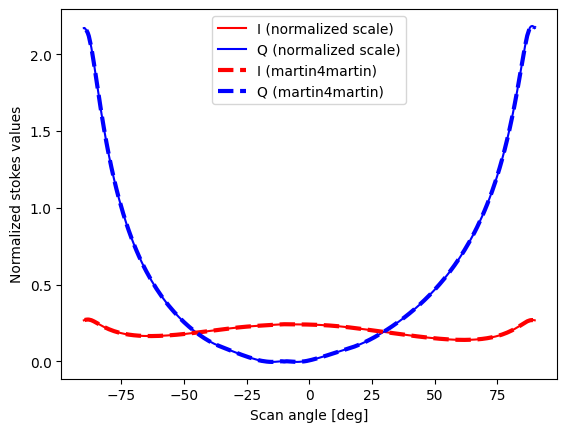

In [4]:
plt.plot(dual_mu_view, I_view, label = "I (normalized scale)",color='r')
plt.plot(dual_mu_view, -10*Q_view, label = "Q (normalized scale)",color='b')
#Load the matlab results and plot them
matlab_I = pd.read_csv(os.path.join("/home/shaizucker/Projects/RTPINN/Data/general/Feng_example", "example_I.csv"), header=None).to_numpy()
plt.plot(matlab_I[:, 0], matlab_I[:, 1], label = "I (martin4martin)", linestyle='--', color='r', linewidth=3)
matlab_Q = pd.read_csv(os.path.join("/home/shaizucker/Projects/RTPINN/Data/general/Feng_example", "example_Q.csv"), header=None).to_numpy()
plt.plot(matlab_Q[:, 0], matlab_Q[:, 1], label = "Q (martin4martin)", linestyle='--', color='b', linewidth=3)
plt.xlabel("Scan angle [deg]")
plt.ylabel("Normalized stokes values")
plt.legend()
plt.show()